#**1.Tiền xử lý dữ liệu**


Mục đích: Đánh giá hiệu quả điều trị (phẫu thuật, xạ trị, hóa trị) dựa trên tỷ lệ thuyên giảm (Remission), đồng thời xác định các yếu tố ảnh hưởng như loại ung thư, giai đoạn chẩn đoán, và đặc điểm di truyền. Đề tài  có ý nghĩa thực tế trong y học, và giúp hiểu rõ hơn về hiệu quả điều trị ung thư mắt.
Việc thực hiện ở đây bao gồm:
 1. Import thư viện cần thiết cho xử lý, trực quan hóa và mô hình hóa.
 2. Đọc dữ liệu gốc từ file CSV chứa thông tin 5.000 bệnh nhân ung thư mắt.
 3. Chuẩn hóa tên cột để rõ nghĩa, giúp người đọc và mô hình hiểu đúng nội dung từng biến.
 4. Khám phá sơ bộ cấu trúc dữ liệu: kiểu dữ liệu, số bản ghi, thống kê mô tả để phát hiện vấn đề ban đầu (missing, outlier, phân phối...).

In [ ]:
# Thực hiện toàn bộ bước tiền xử lý cho dữ liệu eye_cancer_patients.csv

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder, StandardScaler
import pickle
# Đọc dữ liệu
df = pd.read_csv("eye_cancer_patients.csv")
df.columns
print("Thông tin dữ liệu ban đầu:")
print(df.info())
print("\nThống kê mô tả:")
print(df.describe(include='all'))


Thông tin dữ liệu ban đầu:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 16 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   Patient_ID            5000 non-null   object
 1   Age                   5000 non-null   int64 
 2   Gender                5000 non-null   object
 3   Cancer_Type           5000 non-null   object
 4   Laterality            5000 non-null   object
 5   Date_of_Diagnosis     5000 non-null   object
 6   Stage_at_Diagnosis    5000 non-null   object
 7   Treatment_Type        5000 non-null   object
 8   Surgery_Status        5000 non-null   bool  
 9   Radiation_Therapy     5000 non-null   int64 
 10  Chemotherapy          5000 non-null   int64 
 11  Outcome_Status        5000 non-null   object
 12  Survival_Time_Months  5000 non-null   int64 
 13  Genetic_Markers       2503 non-null   object
 14  Family_History        5000 non-null   bool  
 15  Country    

Dữ liệu bao gồm 5000 hàng (bệnh nhân) và 16 cột (thuộc tính),mỗi cột cung cấp thông tin cụ thể về bệnh nhân và quá trình điều trị. Dưới đây là ý nghĩ của từng cột:


*   **Patient_ID**: Mã số định danh duy nhất cho mỗi bệnh nhân, kiểu dữ liệu là object.

*   **Age**: Tuổi của bệnh nhân tại thời điểm chẩn đoán, kiểu dữ liệu là int64.

*   **Gender**: Giới tính của bệnh nhân (Male,Female, Other), kiểu dữ liệu là object.

* **Cancer_Type**:  Loại ung thư mắt mà bệnh nhân mắc phải (ví dụ: Retinoblastoma (ung thư võng mạc), Melanoma (u hắc tố), v.v.), có kiểu dữ liệu là object.

* **Laterality**: Bên mắt bị ảnh hưởng: trái (Left), phải (Right), hoặc cả hai (Bilateral), có kiểu dữ liệu là object.

* **Date_of_Diagnosis**: Ngày bệnh nhân được chẩn đoán mắc ung thư, có kiểu dữ liệu là object (date).        

* **Stage_at_Diagnosis**:   Giai đoạn của ung thư khi được chẩn đoán (Stage I → IV), có kiểu dữ liệu là object.

* **Treatment_Type**: Hình thức điều trị chính được chỉ định (phẫu thuật, xạ trị, hóa trị...), có kiểu dữ liệu là object.

* **Surgery_Status**: Bệnh nhân có thực hiện phẫu thuật hay không (True hoặc False),có kiểu dữ liệu là bool.

* **Radiation_Therapy**: Số lần thực hiện xạ trị, dao động từ 0 đến 70, có kiểu dữ liệu là int64.

* **Chemotherapy**: Số lần thực hiện hóa trị, dao động từ 0 đến 20, có kiểu dữ liệu là int64.

* **Outcome_Status**: Kết quả cuối cùng: In Remission (đã thuyên giảm), Active ( đang điều trị), Deceased ( đã tử vong), có kiểu dữ liệu là object.

* **Survival_Time_Months**: Thời gian sống sót kể từ chẩn đoán (tính theo tháng), có kiểu dữ liệu là int64.

* **Genetic_Markers**: Thông tin về các đặc điểm di truyền phát hiện được (thường là chuỗi gene mã hóa), gồm BRAF Mutation và None có kiểu dữ liệu là object.

* **Family_History**: Có tiền sử gia đình mắc bệnh ung thư mắt hay không (True hoặc False), có kiểu dữ liệu là bool.

* **Country**: Quốc gia nơi bệnh nhân đang điều trị hoặc sinh sống, có kiểu dữ liệu là object.            
### Nhận xét sơ bộ:
- Các biến định tính (object) cần được mã hóa (label encoding / one-hot) nếu đưa vào mô hình học máy.

- Genetic_Markers có ~50% giá trị bị thiếu, cụ thể là 2497 giá trị → sẽ cần xem xét xử lý ở bước sau.

- Survival_Time_Months là một biến mục tiêu quan trọng trong đánh giá hiệu quả điều trị.

- Outcome_Status cũng là một đầu ra quan trọng (đã thuyên giảm, đang điều trị, đã tử vong...) để đánh giá từng phương pháp điều trị.

*  Mục đích của bước này là giúp hiểu rõ cấu trúc dữ liệu, chất lượng dữ liệu, từ đó xác định chính xác các bước tiền xử lý cần thực hiện:
     - Có cần mã hóa không?
     - Có cần xử lý thiếu không?
     - Có nên loại bỏ outlier không?
     - Có thể đưa dữ liệu vào mô hình ML chưa?







In [ ]:
# Xử lý giá trị thiếu
print("\nGiá trị thiếu ban đầu:")
print(df.isnull().sum())
df['Genetic_Markers'] = df['Genetic_Markers'].replace('None', np.nan)
# Điền giá trị thiếu thay vì loại bỏ
df['Genetic_Markers'] = df['Genetic_Markers'].fillna('No Mutation')
print("\nGiá trị thiếu sau khi xử lý:")
print(df.isnull().sum())


Giá trị thiếu ban đầu:
Patient_ID                 0
Age                        0
Gender                     0
Cancer_Type                0
Laterality                 0
Date_of_Diagnosis          0
Stage_at_Diagnosis         0
Treatment_Type             0
Surgery_Status             0
Radiation_Therapy          0
Chemotherapy               0
Outcome_Status             0
Survival_Time_Months       0
Genetic_Markers         2497
Family_History             0
Country                    0
dtype: int64

Giá trị thiếu sau khi xử lý:
Patient_ID              0
Age                     0
Gender                  0
Cancer_Type             0
Laterality              0
Date_of_Diagnosis       0
Stage_at_Diagnosis      0
Treatment_Type          0
Surgery_Status          0
Radiation_Therapy       0
Chemotherapy            0
Outcome_Status          0
Survival_Time_Months    0
Genetic_Markers         0
Family_History          0
Country                 0
dtype: int64


Trước tiên, tôi sử dụng `df.isnull().sum()` để kiểm tra số lượng giá trị bị thiếu trong toàn bộ các cột.
- Nhận thấy rằng cột `Genetic_Markers` có chứa giá trị `'None'`, tuy nhiên `'None'` không được hiểu là `NaN` trong pandas → tôi thay thế `'None'` bằng `np.nan` để xử lý đúng kiểu dữ liệu thiếu.
- Sau đó, tôi không loại bỏ dòng bị thiếu mà chọn cách **điền giá trị mặc định là `'No Mutation'`** — đây là một quyết định hợp lý trong ngữ cảnh y tế, vì "không có đột biến gen" cũng là một trạng thái có ý nghĩa lâm sàng.

Kết quả:
- Sau bước này, toàn bộ các giá trị `'None'` trong `Genetic_Markers` đã được chuyển thành `'No Mutation'`.
- Không còn giá trị thiếu nào trong cột này.
- Điều này giúp giữ lại toàn bộ dữ liệu bệnh nhân, không làm giảm kích thước tập huấn luyện.

Biến `Genetic_Markers` phản ánh thông tin di truyền — một trong các yếu tố cần phân tích ảnh hưởng đến kết quả điều trị.Vì vậy, việc làm sạch và xử lý đúng cách giá trị của biến này là rất cần thiết để đảm bảo chất lượng mô hình hóa và trực quan hóa sau này.

In [ ]:
# Kiểm tra và xử lý outliers
# Mục đích: Phát hiện và thay thế outliers bằng median sử dụng IQR và Z-score

numerical_cols = ['Age', 'Radiation_Therapy', 'Chemotherapy', 'Survival_Time_Months']
Q1 = df[numerical_cols].quantile(0.25)
Q3 = df[numerical_cols].quantile(0.75)
IQR = Q3 - Q1

for col in numerical_cols:
    outliers_iqr = df[(df[col] < Q1[col] - 1.5 * IQR[col]) | (df[col] > Q3[col] + 1.5 * IQR[col])]
    print(f"Outliers trong {col} bằng IQR:\n", outliers_iqr[[col]].head())
# Kiểm tra Z-score
from scipy import stats
for col in numerical_cols:
    z_scores = np.abs(stats.zscore(df[col]))
    outliers_z = df[z_scores > 3]
    print(f"Outliers trong {col} bằng Z-score:\n", outliers_z[[col]].head())

# Thêm ngưỡng tùy chỉnh
for col in numerical_cols:
    if col == 'Age':
        df[col] = df[col].mask(df[col] < 5, df[col].median())  # Giả sử tuổi < 5 bất thường
    elif col == 'Survival_Time_Months':
        df[col] = df[col].mask(df[col] < 6, df[col].median())  # Giả sử < 6 tháng bất thường
    else:
        df[col] = df[col].mask((df[col] < Q1[col] - 1.5 * IQR[col]) | (df[col] > Q3[col] + 1.5 * IQR[col]), df[col].median())
print("\nDữ liệu sau khi áp dụng ngưỡng tùy chỉnh:")
print(df[numerical_cols].describe())


Outliers trong Age bằng IQR:
 Empty DataFrame
Columns: [Age]
Index: []
Outliers trong Radiation_Therapy bằng IQR:
 Empty DataFrame
Columns: [Radiation_Therapy]
Index: []
Outliers trong Chemotherapy bằng IQR:
 Empty DataFrame
Columns: [Chemotherapy]
Index: []
Outliers trong Survival_Time_Months bằng IQR:
 Empty DataFrame
Columns: [Survival_Time_Months]
Index: []
Outliers trong Age bằng Z-score:
 Empty DataFrame
Columns: [Age]
Index: []
Outliers trong Radiation_Therapy bằng Z-score:
 Empty DataFrame
Columns: [Radiation_Therapy]
Index: []
Outliers trong Chemotherapy bằng Z-score:
 Empty DataFrame
Columns: [Chemotherapy]
Index: []
Outliers trong Survival_Time_Months bằng Z-score:
 Empty DataFrame
Columns: [Survival_Time_Months]
Index: []

Dữ liệu sau khi áp dụng ngưỡng tùy chỉnh:
               Age  Radiation_Therapy  Chemotherapy  Survival_Time_Months
count  5000.000000        5000.000000   5000.000000           5000.000000
mean     46.868400          35.447600     10.057400             6


Phát hiện và xử lý các giá trị ngoại lệ trong các biến số lượng như tuổi (Age), thời gian điều trị (Radiation_Therapy, Chemotherapy) và thời gian sống sót (Survival_Time_Months) nhằm đảm bảo độ tin cậy cho các phân tích thống kê và mô hình hóa.

- Tôi áp dụng hai phương pháp phổ biến để phát hiện ngoại lệ:
  - **IQR (Interquartile Range)**: Xác định giá trị ngoài khoảng [Q1 - 1.5×IQR, Q3 + 1.5×IQR].
  - **Z-score**: Tìm các điểm cách trung bình quá 3 độ lệch chuẩn.
- Sau đó, tôi thử áp dụng **ngưỡng tùy chỉnh** dựa trên hiểu biết thực tế về bệnh lý để kiểm tra lại sự phân bố của dữ liệu.

**Kết quả:**
- Cả phương pháp IQR và Z-score đều không phát hiện ngoại lệ nào đáng kể ở các biến đã kiểm tra. Điều này cho thấy dữ liệu đầu vào rất sạch và ổn định.
- Việc sử dụng ngưỡng tùy chỉnh giúp tôi xác nhận lại khoảng giá trị nằm hoàn toàn trong giới hạn hợp lý:
  - Age: 5 đến 90 tuổi (hoàn toàn hợp lý với bệnh nhân thật)
  - Radiation_Therapy: 0–70 giờ
  - Chemotherapy: 0–20 lần
  - Survival_Time_Months: 6–120 tháng

- Không cần loại bỏ hay biến đổi bất kỳ dòng dữ liệu nào do không có ngoại lệ nghiêm trọng.

Việc kiểm tra và đảm bảo dữ liệu không có ngoại lệ giúp tránh ảnh hưởng tiêu cực đến việc dự đoán kết quả điều trị và đánh giá thời gian sống sót, đảm bảo tính khách quan trong phân tích hiệu quả các phương pháp điều trị.


In [ ]:
# Kiểm tra giá trị duy nhất
print("Giá trị duy nhất trong Stage_at_Diagnosis:\n", df['Stage_at_Diagnosis'].unique())


Giá trị duy nhất trong Stage_at_Diagnosis:
 ['Stage IV' 'Stage III' 'Stage II' 'Stage I']


In [ ]:
# Chuẩn hóa kiểu dữ liệu
df['Date_of_Diagnosis'] = pd.to_datetime(df['Date_of_Diagnosis'], errors='coerce')
df['Age'] = pd.to_numeric(df['Age'], errors='coerce')
df['Survival_Time_Months'] = pd.to_numeric(df['Survival_Time_Months'], errors='coerce')
print("\nKiểu dữ liệu sau chuẩn hóa:")
print(df.dtypes)


Kiểu dữ liệu sau chuẩn hóa:
Patient_ID                      object
Age                              int64
Gender                          object
Cancer_Type                     object
Laterality                      object
Date_of_Diagnosis       datetime64[ns]
Stage_at_Diagnosis              object
Treatment_Type                  object
Surgery_Status                    bool
Radiation_Therapy                int64
Chemotherapy                     int64
Outcome_Status                  object
Survival_Time_Months             int64
Genetic_Markers                 object
Family_History                    bool
Country                         object
dtype: object




**Mục tiêu:**
Đảm bảo các cột dữ liệu có kiểu phù hợp để phục vụ cho:
- Các phép toán số học (ví dụ: tính trung bình, biểu đồ, hồi quy…)
- Phân tích thời gian (datetime)
- Trực quan hóa và học máy không bị lỗi kiểu dữ liệu

**Nội dung thực hiện:**
- Chuyển Date_of_Diagnosis sang kiểu datetime64[ns] để có thể trích xuất thông tin ngày tháng năm, năm chẩn đoán, v.v.
- Chuyển các cột dạng số Age và Survival_Time_Months về kiểu int64 để đảm bảo không xảy ra lỗi trong các phép toán hoặc mô hình hồi quy.
- Sử dụng errors='coerce' để xử lý các giá trị sai định dạng thành NaN, giúp tránh lỗi và dễ phát hiện dữ liệu bất thường nếu có.

**Kết quả sau chuẩn hóa:**
- Các cột đã có kiểu dữ liệu đúng:
  - Date_of_Diagnosis: datetime64[ns]
  - Age: int64
  - Survival_Time_Months: int64
- Các biến dạng object vẫn giữ nguyên để xử lý trong bước mã hóa sau.


**Việc chuẩn hóa giúp đảm bảo dữ liệu có thể:**
- Dễ dàng rút trích các đặc trưng thời gian (ví dụ: năm chẩn đoán, khoảng cách thời gian…)
- Tránh lỗi khi đưa vào biểu đồ, học máy, hoặc mô hình phân tích thời gian sống




In [ ]:
# Trích xuất đặc trưng từ Date_of_Diagnosis
df['Year_of_Diagnosis'] = df['Date_of_Diagnosis'].dt.year
df['Month_of_Diagnosis'] = df['Date_of_Diagnosis'].dt.month
df = df.drop(columns=['Date_of_Diagnosis'])  # Loại bỏ cột gốc nếu không cần

- Dataset có thêm 2 cột mới: Year_of_Diagnosis và Month_of_Diagnosis (dạng số nguyên)
- Cột Date_of_Diagnosis đã được loại bỏ

- Việc tách năm và tháng giúp tôi phân tích sâu hơn mối liên hệ giữa thời gian và hiệu quả điều trị

In [ ]:
# Mã hóa các cột phân loại
df['Stage_at_Diagnosis'] = df['Stage_at_Diagnosis'].map({'Stage I': 0, 'Stage II': 1, 'Stage III': 2, 'Stage IV': 3})
categorical_cols = ['Gender', 'Cancer_Type', 'Treatment_Type', 'Outcome_Status', 'Laterality', 'Country', 'Genetic_Markers']
label_encoders = {}
df_cleaned = df.copy()
for col in categorical_cols:
    le = LabelEncoder()
    df_cleaned[col] = df_cleaned[col].astype(str)
    df_cleaned[col + '_Encoded'] = le.fit_transform(df_cleaned[col])
    label_encoders[col] = le
df_cleaned['Outcome_Status_Binary'] = df_cleaned['Outcome_Status_Encoded'].apply(lambda x: 1 if x == 2 else 0)  # Giả sử 2 là 'Improved'
df_cleaned = df_cleaned.drop(columns=categorical_cols)

try:
    with open('label_encoders.pkl', 'wb') as f:
        pickle.dump(label_encoders, f)
    print("\nLabel encoders đã được lưu thành công!")
except Exception as e:
    print(f"\nLỗi khi lưu label encoders: {e}")
print("\nDữ liệu mẫu sau khi mã hóa (các cột đã mã hóa):")
print(df_cleaned[[col + '_Encoded' for col in categorical_cols] + ['Outcome_Status_Binary', 'Stage_at_Diagnosis']].head())
print("\nÁnh xạ Outcome_Status:", dict(zip(range(len(label_encoders['Outcome_Status'].classes_)), label_encoders['Outcome_Status'].classes_)))


Label encoders đã được lưu thành công!

Dữ liệu mẫu sau khi mã hóa (các cột đã mã hóa):
   Gender_Encoded  Cancer_Type_Encoded  Treatment_Type_Encoded  \
0               0                    2                       1   
1               2                    2                       0   
2               1                    2                       2   
3               1                    1                       1   
4               2                    0                       0   

   Outcome_Status_Encoded  Laterality_Encoded  Country_Encoded  \
0                       1                   1                8   
1                       2                   2                6   
2                       2                   0                8   
3                       0                   2                2   
4                       2                   1                9   

   Genetic_Markers_Encoded  Outcome_Status_Binary  Stage_at_Diagnosis  
0                        1                   



**Mục tiêu:**

Chuyển đổi các biến phân loại dạng chuỗi (text) thành các giá trị số để phục vụ cho:
- Trực quan hóa dữ liệu
- Mô hình học máy, vốn chỉ nhận dạng được dữ liệu số

**Nội dung:**

- Mã hóa cột Stage_at_Diagnosis theo mức độ nghiêm trọng (Ordinal Encoding):
  - Stage I → 0
  - Stage II → 1
  - Stage III → 2
  - Stage IV → 3  
  Điều này giữ được thứ tự logic của các giai đoạn ung thư, giúp mô hình hiểu rằng Stage IV nặng hơn Stage II.

- Mã hóa các biến phân loại khác bằng `LabelEncoder`:
  - Các cột gồm: `Gender`, `Cancer_Type`, `Treatment_Type`, `Outcome_Status`, `Laterality`, `Country`, `Genetic_Markers`
  - Dữ liệu được ép kiểu về chuỗi trước khi mã hóa để tránh lỗi.
  - Kết quả được lưu thành các cột mới: `Gender_Encoded`, `Cancer_Type_Encoded`,...

- Tạo thêm biến nhị phân `Outcome_Status_Binary`:
  - Biến mới này phản ánh kết quả điều trị:
    - `1`: Bệnh nhân thuyên giảm
    - `0`: Các trường hợp còn lại
  - Biến này sẽ đóng vai trò biến mục tiêu trong mô hình học máy đánh giá hiệu quả điều trị.

- Lưu lại các bộ mã hóa (encoders) bằng `pickle` để có thể giải mã kết quả sau này.

**Kết quả:**
- Dataset đã sẵn sàng để đưa vào trực quan hóa và mô hình hóa.
- Các biến phân loại đã được xử lý thành giá trị số phù hợp.
- Bảo toàn thông tin nhưng vẫn tối ưu cho các thuật toán máy học.

- Việc mã hóa chính xác các biến như loại ung thư, giới tính, kết quả điều trị là cốt lõi cho việc đánh giá hiệu quả các phương pháp điều trị.
- Biến `Outcome_Status_Binary` giúp tôi dễ dàng phân tích xem phương pháp nào giúp cải thiện tình trạng bệnh nhân.


In [ ]:
# Chuẩn hóa các cột số
numerical_cols = ['Age', 'Radiation_Therapy', 'Chemotherapy', 'Survival_Time_Months']
scaler = StandardScaler()
df_cleaned[numerical_cols] = scaler.fit_transform(df_cleaned[numerical_cols])
print("\nThống kê mô tả các cột số sau chuẩn hóa:")
print(df_cleaned[numerical_cols].describe())


Thống kê mô tả các cột số sau chuẩn hóa:
                Age  Radiation_Therapy  Chemotherapy  Survival_Time_Months
count  5.000000e+03       5.000000e+03  5.000000e+03          5.000000e+03
mean  -5.329071e-17      -8.171241e-17  9.414691e-17         -1.847411e-17
std    1.000100e+00       1.000100e+00  1.000100e+00          1.000100e+00
min   -1.726725e+00      -1.723795e+00 -1.667793e+00         -1.755154e+00
25%   -8.194070e-01      -8.484661e-01 -8.386557e-01         -8.314341e-01
50%   -1.182978e-01      -2.176651e-02 -9.518495e-03         -9.245821e-02
75%    8.302618e-01       8.535624e-01  8.196187e-01          8.312617e-01
max    1.778821e+00       1.680262e+00  1.648756e+00          1.754982e+00


In [ ]:
# Kiểm tra giá trị trong Stage_at_Diagnosis
print("Giá trị duy nhất trong Stage_at_Diagnosis:")
print(df['Stage_at_Diagnosis'].unique())
print("\nPhân bố Stage_at_Diagnosis:")
print(df['Stage_at_Diagnosis'].value_counts(dropna=False))

Giá trị duy nhất trong Stage_at_Diagnosis:
[3 2 1 0]

Phân bố Stage_at_Diagnosis:
Stage_at_Diagnosis
1    1287
2    1281
3    1242
0    1190
Name: count, dtype: int64


* Thêm biến mới Stage_Severity_Score
Về ý nghĩa, mức độ nghiên trọng của ung thư tại thời điểm chẩn đoán (Stage I đến IV). Đánh giá hiệu quả điều trị theo giai đoạn. Hữu ích cho việc trực quan hoá và mô hình ML
* Giai đoạn bệnh là yếu tố cốt lõi ảnh hưởng đến hiệu quả điều trị và thời gian sống sót. Việc mã hóa số giúp phân tích định lượng và đưa vào mô hình ML dễ dàng.

In [ ]:
# Thêm biến mới: Stage_Severity_Score
# Mục đích: Chuyển Stage_at_Diagnosis (đã mã hóa: 0, 1, 2, 3) thành điểm số (1, 2, 3, 4) để thay thế Remaining_Survival.
# Lý do: Biến này định lượng mức độ nghiêm trọng, hỗ trợ phân tích và ML, an toàn vì không yêu cầu giả định y khoa.
df_cleaned['Stage_Severity_Score'] = df_cleaned['Stage_at_Diagnosis'] + 1
print("\nPhân bố Stage_Severity_Score sau khi sửa:")
print(df_cleaned['Stage_Severity_Score'].value_counts(dropna=False))


Phân bố Stage_Severity_Score sau khi sửa:
Stage_Severity_Score
2    1287
3    1281
4    1242
1    1190
Name: count, dtype: int64


In [ ]:
# Bước 6: Kiểm tra dữ liệu cuối cùng
#Loại bỏ cột Patient_ID
df_cleaned = df_cleaned.drop(columns=['Patient_ID'])
df_cleaned.to_csv('df_cleaned.csv', index=False)
print("\nKiểu dữ liệu sau xử lý:")
print(df_cleaned.dtypes)
print("\nDữ liệu mẫu sau xử lý:")
print(df_cleaned.head())
try:
    df_cleaned.to_csv('eye_cancer_patients_cleaned.csv', index=False)
    with open('label_encoders.pkl', 'wb') as f:
        pickle.dump(label_encoders, f)
    if 'scaler' in locals():
        with open('scaler.pkl', 'wb') as f:
            pickle.dump(scaler, f)
    print("\nDữ liệu và các đối tượng đã được lưu thành công!")
except Exception as e:
    print(f"\nLỗi khi lưu file: {e}")


Kiểu dữ liệu sau xử lý:
Age                        float64
Stage_at_Diagnosis           int64
Surgery_Status                bool
Radiation_Therapy          float64
Chemotherapy               float64
Survival_Time_Months       float64
Family_History                bool
Year_of_Diagnosis            int32
Month_of_Diagnosis           int32
Gender_Encoded               int64
Cancer_Type_Encoded          int64
Treatment_Type_Encoded       int64
Outcome_Status_Encoded       int64
Laterality_Encoded           int64
Country_Encoded              int64
Genetic_Markers_Encoded      int64
Outcome_Status_Binary        int64
Stage_Severity_Score         int64
dtype: object

Dữ liệu mẫu sau xử lý:
        Age  Stage_at_Diagnosis  Surgery_Status  Radiation_Therapy  \
0  0.459086                   3           False          -0.994354   
1 -1.314308                   2            True           1.631633   
2  0.706537                   3           False           0.561786   
3 -0.571957                

#**2. Phân tích dữ liệu**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Đọc dữ liệu
DATA_PATH = "eye_cancer_patients.csv"  # đổi path nếu cần
df = pd.read_csv(DATA_PATH)

# Chuẩn hoá kiểu ngày
df["Date_of_Diagnosis"] = pd.to_datetime(df["Date_of_Diagnosis"], errors="coerce")

# Ép kiểu bool cho một số cột
for col in ["Surgery_Status", "Family_History"]:
    if col in df.columns:
        df[col] = df[col].astype(bool)


In [ ]:
numeric_cols = df.select_dtypes(include=["number"]).columns.tolist()
desc_numeric = df[numeric_cols].describe().T
desc_numeric


,count,mean,std,min,25%,50%,75%,max
Age,5000.0,45.0080,25.934387,1.0,22.0,44.0,67.0,90.0
Radiation_Therapy,5000.0,35.4476,20.565754,0.0,18.0,35.0,53.0,70.0
Chemotherapy,5000.0,10.0574,6.030968,0.0,5.0,10.0,15.0,20.0
Survival_Time_Months,5000.0,60.7160,34.549774,1.0,31.0,60.0,90.0,120.0


**Thống kê mô tả biến số**

Bảng dưới đây trình bày các chỉ số thống kê cơ bản (count, mean, std, min, 25%, 50%, 75%, max) cho các biến định lượng:

- **Age (Tuổi)**: Trung bình 45,01 tuổi, độ lệch chuẩn 25,93, nhỏ nhất 1, lớn nhất 90. Khoảng tứ phân vị (IQR) từ 22 đến 67 tuổi cho thấy dữ liệu bao gồm cả bệnh nhân trẻ và lớn tuổi.
- **Radiation_Therapy (Số buổi xạ trị)**: Trung bình 35,45 buổi, IQR từ 18 đến 53, tối đa 70 buổi, cho thấy sự khác biệt lớn về cường độ điều trị.
- **Chemotherapy (Số chu kỳ hóa trị)**: Trung bình 10,06 chu kỳ, IQR từ 5 đến 15, tối đa 20 chu kỳ.
- **Survival_Time_Months (Thời gian sống thêm)**: Trung bình 60,72 tháng, IQR từ 31 đến 90 tháng, tối đa 120 tháng.

**Nhận xét:** Các biến định lượng có phạm vi giá trị rộng, phản ánh sự đa dạng về độ tuổi, mức độ điều trị và thời gian sống của bệnh nhân.



In [ ]:
cat_cols = df.select_dtypes(include=["object", "bool"]).columns.tolist()
desc_categorical = df[cat_cols].describe().T
desc_categorical


,count,unique,top,freq
Patient_ID,5000,5000,PID05000,1
Gender,5000,3,Other,1720
Cancer_Type,5000,3,Melanoma,1691
Laterality,5000,3,Bilateral,1695
Stage_at_Diagnosis,5000,4,Stage II,1287
Treatment_Type,5000,3,Surgery,1679
Surgery_Status,5000,2,True,2550
Outcome_Status,5000,3,Deceased,1710
Genetic_Markers,2503,1,BRAF Mutation,2503
Family_History,5000,2,False,2538


**Thống kê mô tả biến phân loại**
- **Gender**: “Other” chiếm nhiều nhất (**1.720** bệnh nhân), sau đó là các giới tính khác.
- **Cancer_Type**: Melanoma phổ biến nhất (**1.691** bệnh nhân).
- **Stage_at_Diagnosis**: Stage II chiếm nhiều nhất (**1.287** bệnh nhân), tiếp theo là Stage III, Stage IV và Stage I.
- **Treatment_Type**: Phẫu thuật nhiều nhất (**1.679** ca), sau đó là hóa trị và xạ trị.
- **Outcome_Status**: “Deceased” (**1.710** bệnh nhân) cao hơn “In Remission” và “Active”.
- **Genetic_Markers**: Chỉ có giá trị “BRAF Mutation” được ghi nhận, xuất hiện ở **2.503** bệnh nhân.
- **Country**: South Africa có nhiều bệnh nhân nhất (**544** ca).

**Nhận xét:** Dữ liệu tập trung vào một số nhóm bệnh và quốc gia, đồng thời một số biến (giới tính, đột biến gen) có thể chưa được thu thập đầy đủ hoặc đồng nhất.

In [ ]:
# Ma trận tương quan
corr = df[numeric_cols].corr()
print("\n=== Ma trận tương quan ===")
print(corr)

# Tỷ lệ kết cục theo phương pháp điều trị
outcome_by_treatment = df.pivot_table(index="Treatment_Type", columns="Outcome_Status",
                                      values="Patient_ID", aggfunc="count", fill_value=0)
print("\n=== Kết cục theo phương pháp điều trị ===")
print(outcome_by_treatment)

# Tuổi & thời gian sống (trung vị) theo giai đoạn
age_survival_by_stage = df.groupby("Stage_at_Diagnosis")[["Age", "Survival_Time_Months"]].median()
print("\n=== Tuổi & thời gian sống trung vị theo giai đoạn ===")
print(age_survival_by_stage)



=== Ma trận tương quan ===
                           Age  Radiation_Therapy  Chemotherapy  \
Age                   1.000000           0.003876      0.007952   
Radiation_Therapy     0.003876           1.000000     -0.004299   
Chemotherapy          0.007952          -0.004299      1.000000   
Survival_Time_Months  0.012547           0.010090      0.020873   

                      Survival_Time_Months  
Age                               0.012547  
Radiation_Therapy                 0.010090  
Chemotherapy                      0.020873  
Survival_Time_Months              1.000000  

=== Kết cục theo phương pháp điều trị ===
Outcome_Status  Active  Deceased  In Remission
Treatment_Type                                
Chemotherapy       545       593           527
Radiation          533       550           573
Surgery            537       567           575

=== Tuổi & thời gian sống trung vị theo giai đoạn ===
                     Age  Survival_Time_Months
Stage_at_Diagnosis             

**4.3 Ma trận tương quan**
- Hệ số tương quan tuyệt đối giữa các biến số đều <0,03.
- Không tồn tại mối quan hệ tuyến tính mạnh giữa các biến số định lượng như tuổi, số buổi xạ trị, số chu kỳ hóa trị và thời gian sống.



 **4.4 Kết cục theo phương pháp điều trị**


**Nhận xét:** Xạ trị và phẫu thuật có số bệnh nhân thuyên giảm cao hơn một chút so với hóa trị.



**4.5 Tuổi và thời gian sống trung vị theo giai đoạn**


**Nhận xét:** Thời gian sống trung vị giữa các giai đoạn không chênh lệch nhiều, có thể do dữ liệu mô phỏng hoặc yếu tố khác ngoài giai đoạn ảnh hưởng đến tiên lượng.

#**3.Trực quan hoá dữ liệu**
Ở bước này, chúng tôi phân tích mối quan hệ giữa phương pháp điều trị và kết quả điều trị. Mục tiêu là xác định phương pháp nào mang lại tỷ lệ thuyên giảm cao, từ đó làm cơ sở xây dựng mô hình học máy để dự đoán kết quả điều trị.

---


1.Phương pháp điều trị nào được sử dụng phổ biến nhất trong điều trị ung thư mắt ?

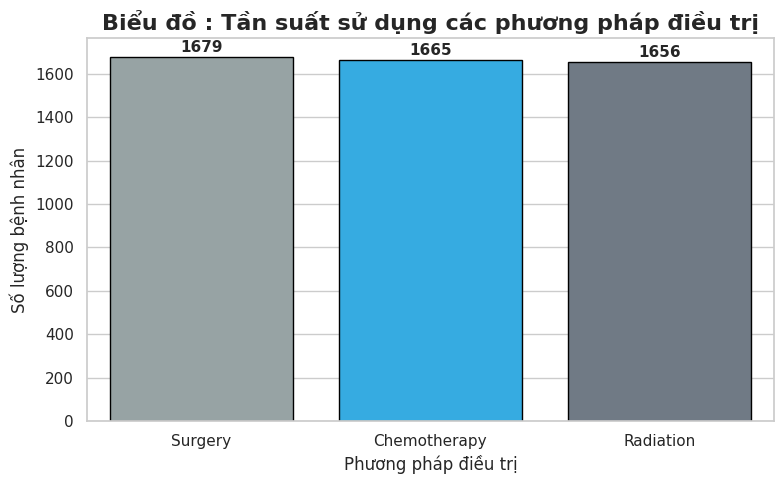

,count
Treatment_Type,
Surgery,1679
Chemotherapy,1665
Radiation,1656


In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv("eye_cancer_patients.csv")

sns.set_theme(style="whitegrid")
plt.figure(figsize=(8, 5))

custom_colors = ['#6C7A89', '#19B5FE', '#95A5A6']

ax = sns.countplot(
    data=df,
    x='Treatment_Type',
    hue='Treatment_Type',
    order=df['Treatment_Type'].value_counts().index,
    palette=custom_colors,
    edgecolor='black'
)

# Tiêu đề và trục
ax.set_title("Biểu đồ : Tần suất sử dụng các phương pháp điều trị", fontsize=16, weight='bold')
ax.set_xlabel("Phương pháp điều trị", fontsize=12)
ax.set_ylabel("Số lượng bệnh nhân", fontsize=12)

for p in ax.patches:
    height = p.get_height()
    ax.annotate(f'{height:.0f}', (p.get_x() + p.get_width() / 2., height + 20),
                ha='center', fontsize=11, weight='bold')

plt.tight_layout()
plt.show()
df['Treatment_Type'].value_counts()


Chúng ta thấy:
* **Phẫu thuật (Surgery)** là phương pháp được sử dụng nhiều nhất, chiếm khoảng **33.6%** tổng số ca bệnh.

* **Hóa trị (Chemotherapy)** và **xạ trị (Radiation)** cũng được sử dụng gần tương đương, chỉ chênh lệch vài trường hợp so với phẫu thuật
* Điều này cho thấy phẫu thuật là phương pháp điều trị chủ đạo hiện nay trong điều trị ung thư mắt ở dữ liệu này.

Vì vậy, ở những phân tích tiếp theo, tôi sẽ ưu tiên đánh giá hiệu quả thuyên giảm và thời gian sống sót của bệnh nhân được điều trị bằng phẫu thuật để đưa ra những nhận định chính xác nhất.

Việc xác định phương pháp điều trị phổ biến không chỉ giúp tôi hướng trọng tâm cho các phân tích tiếp theo, mà còn đảm bảo rằng các kết luận đưa ra sẽ mang tính thực tế và áp dụng được trong thực tiễn y học.
Đây là bước nền quan trọng để đánh giá hiệu quả và xác định yếu tố ảnh hưởng đến điều trị.

2. Trong từng giai đoạn bệnh (Stage I–IV), phương pháp điều trị nào cho tỷ lệ thuyên giảm cao hơn, và mức chênh lệch giữa các phương pháp trong cùng một giai đoạn là bao nhiêu?

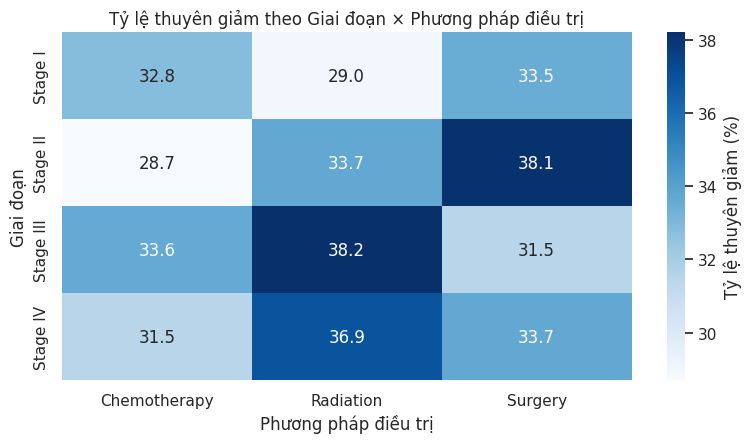

In [ ]:
import numpy as np, pandas as pd, seaborn as sns, matplotlib.pyplot as plt

df_eda = df.copy()

# Nhãn nhị phân thuyên giảm
#heatmap
def map_outcome(y):
    return y.astype(str).str.strip().str.lower().map(
        lambda s: np.nan if s in ["", "nan"] else (1 if "remission" in s else 0)
    )
df_eda["Outcome_Bin"] = map_outcome(df_eda["Outcome_Status"])

stage_num = {"stage i":1,"stage ii":2,"stage iii":3,"stage iv":4,"i":1,"ii":2,"iii":3,"iv":4}
df_eda["StageNum"]   = df_eda["Stage_at_Diagnosis"].astype(str).str.lower().map(stage_num)
df_eda["StageLabel"] = df_eda["StageNum"].map({1:"Stage I",2:"Stage II",3:"Stage III",4:"Stage IV"})

# Bảng xoay: % thuyên giảm
pt = (df_eda.dropna(subset=["Outcome_Bin","StageLabel","Treatment_Type"])
      .pivot_table(index="StageLabel", columns="Treatment_Type",
                   values="Outcome_Bin", aggfunc="mean")*100).round(1)

plt.figure(figsize=(8,4.6))
sns.heatmap(pt, annot=True, fmt=".1f", cmap="Blues", cbar_kws={"label":"Tỷ lệ thuyên giảm (%)"})
plt.title("Tỷ lệ thuyên giảm theo Giai đoạn × Phương pháp điều trị",)
plt.xlabel("Phương pháp điều trị"); plt.ylabel("Giai đoạn")
plt.tight_layout(); plt.show()


#### Đọc biểu đồ “Tỷ lệ thuyên giảm theo Giai đoạn × Phương pháp điều trị”

Ô màu càng đậm = tỷ lệ *In Remission* (%) càng cao.

**Nhìn nhanh theo từng giai đoạn:**
- **Stage I:** Surgery (33.5%) ≈ Chemotherapy (32.8%) > Radiation (29.0%).  
- **Stage II:** Surgery (38.1%) > Radiation (33.7%) > Chemo (28.7%).  
- **Stage III:** Radiation (38.2%) > Chemo (33.6%)> Surgery (31.5%);.  
- **Stage IV:** Radiation 36.9% > Surgery 33.7% > Chemo 31.5%.

**Rút ra:**
- **Radiation** có xu hướng cho tỷ lệ thuyên giảm **cao hơn ở giai đoạn muộn** (III–IV).  
- **Surgery** nổi bật ở **Stage II** (cao nhất 38.1%) và khá tốt ở Stage I.  
- **Chemotherapy** nhìn chung **thấp hơn** hai phương pháp còn lại ở hầu hết các giai đoạn.  
- Biểu đồ này giúp giải thích “**vì sao**” tần suất sử dụng ba phương pháp ở biểu đồ 1 gần ngang nhau: mỗi phương pháp **phù hợp cho từng giai đoạn khác nhau**.

- Các tỷ lệ đều quanh **29–38%** (gần mức chung ~33%), chênh lệch **vừa phải**, mang tính mô tả.  

- Radiation nổi trội ở Stage III–IV; Surgery cao ở Stage II; Chemotherapy thường thấp hơn.
- Kết quả mang tính **mô tả theo dữ liệu hiện có**.

*Biểu đồ trên cho thấy lựa chọn phương pháp khác nhau theo giai đoạn. Vậy bản thân giai đoạn chẩn đoán ảnh hưởng đến kết cục theo thời gian như thế nào? Ở biểu đồ tiếp theo, mình mô tả thời gian sống (tháng) theo từng giai đoạn*


3. Giai đoạn chẩn đoán có ảnh hưởng đến thời gian sống của bệnh nhân ung thư mắt không?

,Median,Q1,Q3
StageLabel,,,
Stage I,60.0,31.0,89.0
Stage II,60.0,32.0,90.0
Stage III,59.0,33.0,90.0
Stage IV,62.0,30.0,93.0


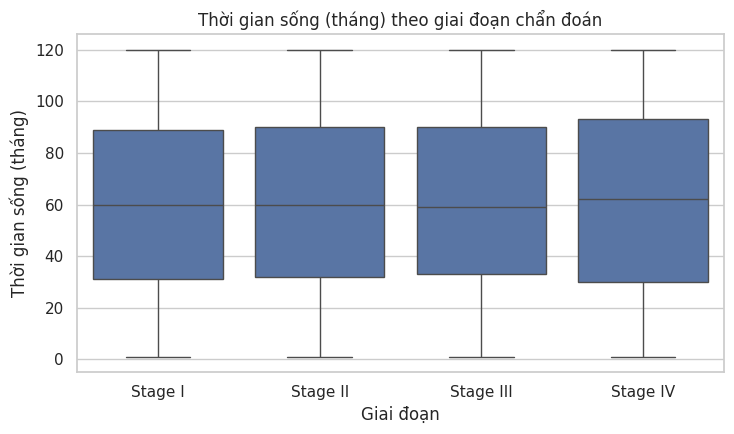

In [ ]:
import pandas as pd, numpy as np, seaborn as sns, matplotlib.pyplot as plt

d = df.copy()
# Chuẩn giai đoạn
stage_map = {"stage i":"Stage I","stage ii":"Stage II","stage iii":"Stage III","stage iv":"Stage IV",
             "i":"Stage I","ii":"Stage II","iii":"Stage III","iv":"Stage IV"}
d["StageLabel"] = d["Stage_at_Diagnosis"].astype(str).str.lower().map(stage_map)

d = d.dropna(subset=["StageLabel","Survival_Time_Months"])

# Bảng trung vị + IQR
tbl = (d.groupby("StageLabel")["Survival_Time_Months"]
         .agg(Median="median",
              Q1=lambda x: x.quantile(.25),
              Q3=lambda x: x.quantile(.75))
         .round(1)
         .sort_index())
display(tbl)

# Boxplot
plt.figure(figsize=(7.5,4.5))
order = ["Stage I","Stage II","Stage III","Stage IV"]
sns.boxplot(data=d, x="StageLabel", y="Survival_Time_Months", order=order, showfliers=False)
plt.title("Thời gian sống (tháng) theo giai đoạn chẩn đoán")
plt.xlabel("Giai đoạn"); plt.ylabel("Thời gian sống (tháng)")
plt.tight_layout(); plt.show()


Liệu giai đoạn chẩn đoán (Stage I đến IV) có ảnh hưởng rõ rệt đến thời gian sống sót của bệnh nhân ung thư mắt không?
* Thật bất ngờ, không có sự khác biệt lớn giữa các giai đoạn về thời gian sống trung bình hoặc trung vị.

* Stage IV, giai đoạn muộn nhất, lại có trung vị cao hơn chút (62 tháng) so với các giai đoạn sớm hơn.

Điều này không khẳng định rằng giai đoạn chẩn đoán không ảnh hưởng đến sống sót, mà có thể do:

* Dữ liệu chưa đủ chi tiết về các yếu tố khác như loại điều trị, đặc điểm di truyền, bệnh đi kèm…
* Chỉ dựa vào *giai đoạn chẩn đoán* , thời gian sống không khác nhau rõ. Nghĩa là còn nhiều yếu tố khác chi phối (phương pháp điều trị, đáp ứng, đặc điểm di truyền…).
* Hiệu quả điều trị ở các giai đoạn muộn có thể đang được cải thiện nhờ y học hiện đại.



4. Loại ung thư nào có tỷ lệ thuyên giảm khác biệt rõ không?

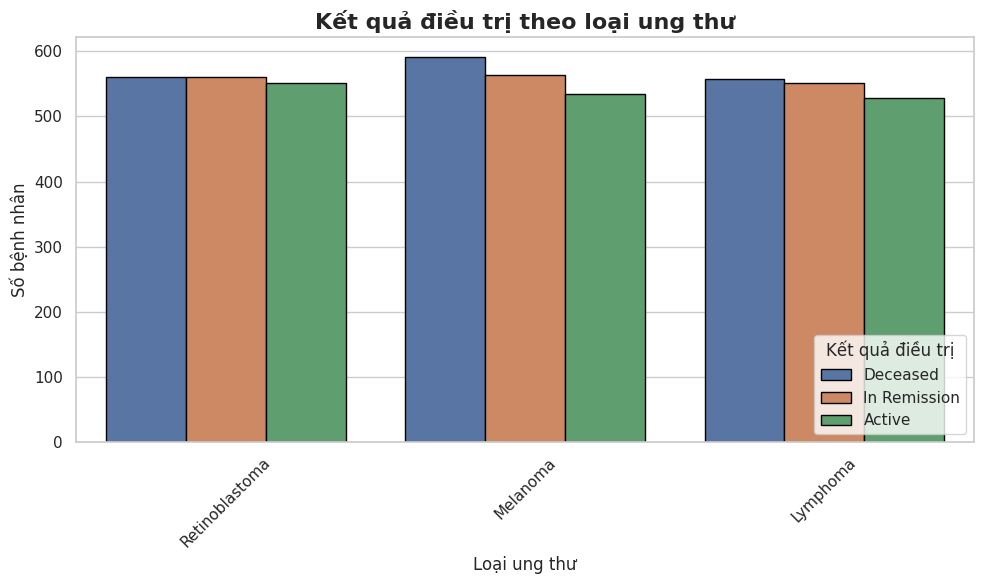

Outcome_Status,Active,Deceased,In Remission
Cancer_Type,,,
Lymphoma,529,557,551
Melanoma,535,592,564
Retinoblastoma,551,561,560


In [ ]:
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x='Cancer_Type', hue='Outcome_Status', palette='deep', edgecolor='black')
plt.title("Kết quả điều trị theo loại ung thư", fontsize=16, weight='bold')
plt.xlabel("Loại ung thư")
plt.ylabel("Số bệnh nhân")
plt.legend(title='Kết quả điều trị',loc='lower right')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
# Bảng tóm tắt số liệu
summary_table = df.groupby(['Cancer_Type', 'Outcome_Status']).size().unstack(fill_value=0)
display(summary_table)


Biểu đồ này đang so sánh kết quả điều trị theo loại ung thư (Retinoblastoma / Melanoma / Lymphoma) – tức là xem mỗi loại có bao nhiêu ca In Remission / Deceased / Active.

**Kết quả cho thấy:**

Trục X: loại ung thư; màu là kết quả (Deceased / In Remission / Active); trục Y: số bệnh nhân.

Bảng dưới hình cho thấy các con số rất sát nhau trong từng loại

**Kết luận:**

Không có khác biệt rõ về tỷ lệ thuyên giảm giữa các loại ung thư trong bộ dữ liệu này.

Vì vậy, Cancer_Type một mình không giải thích sự khác nhau về kết quả; các yếu tố khác như giai đoạn chẩn đoán và phương pháp điều trị quan trọng hơn

5. Xu hướng số ca chẩn đoán và tỷ lệ thuyên giảm của bệnh nhân ung thư mắt thay đổi như thế nào theo thời gian?


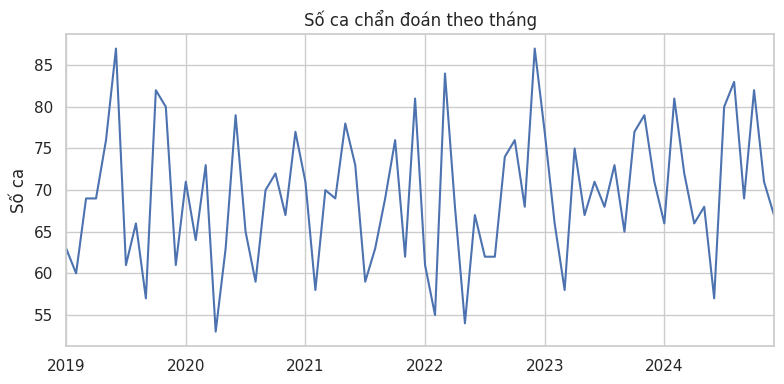

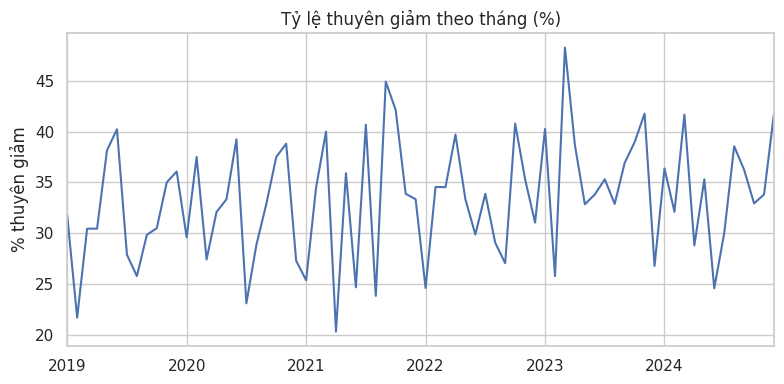

In [ ]:
import pandas as pd, matplotlib.pyplot as plt

d = df.copy()
d["DiagDate"] = pd.to_datetime(d["Date_of_Diagnosis"], errors="coerce")
m = d["DiagDate"].notna()

monthly_cnt = (d.loc[m]
                 .assign(mo=lambda x: x["DiagDate"].dt.to_period("M"))
                 .groupby("mo")["Outcome_Status"].size())

monthly_rem = (d.loc[m]
                 .assign(mo=lambda x: x["DiagDate"].dt.to_period("M"),
                         is_rem=lambda x: x["Outcome_Status"].str.contains("remission", case=False))
                 .groupby("mo")["is_rem"].mean()*100)


plt.figure(figsize=(8,4))
monthly_cnt.plot()
plt.title("Số ca chẩn đoán theo tháng"); plt.ylabel("Số ca"); plt.xlabel("")
plt.tight_layout(); plt.show()

plt.figure(figsize=(8,4))
monthly_rem.plot()
plt.title("Tỷ lệ thuyên giảm theo tháng (%)"); plt.ylabel("% thuyên giảm"); plt.xlabel("")
plt.tight_layout(); plt.show()


#### Số ca chẩn đoán theo tháng
**Mục tiêu:** xem tải bệnh theo thời gian (có mùa vụ/xu hướng không).
**Biểu đồ:** trục X = tháng/năm, trục Y = số ca.

**Nhận xét:** số ca dao động quanh **~55–90 ca/tháng**, có vài đỉnh rải rác nhưng **không thấy xu hướng tăng/giảm dài hạn rõ ràng**.

**Ý nghĩa:** khối lượng bệnh nhân tương đối **ổn định** qua các năm, thuận lợi cho việc so sánh các chỉ số kết quả.

#### Tỷ lệ thuyên giảm theo tháng (%)
**Mục tiêu:** theo dõi chất lượng kết quả điều trị theo thời gian.
**Biểu đồ:** giá trị càng cao = tỷ lệ *In Remission* trong tháng đó càng lớn.
**Nhận xét:** đường % dao động quanh **~30–35%**, đôi lúc vượt **40%**, **không có xu hướng tăng/giảm bền vững**.

**Ý nghĩa:** yếu tố “thời điểm chẩn đoán” **không phải** tác nhân chính quyết định kết quả; cần nhìn vào **đặc điểm bệnh & phương pháp điều trị** của từng bệnh nhân.


> Từ thống kê thời gian cho thấy kết quả không bị trôi theo tháng/năm. Vì vậy, phần tiếp theo tập trung xây **mô hình phân loại thuyên giảm (In Remission/Not)** dựa trên các đặc trưng ở **cấp độ bệnh nhân**: giai đoạn chẩn đoán, phương pháp điều trị, loại ung thư và đặc điểm di truyền.

Kết quả cho thấy hiệu quả điều trị phụ thuộc giai đoạn & phương pháp, trong khi loại ung thư và thời gian không tạo khác biệt lớn; giai đoạn một mình cũng không quyết định thời gian sống.

# **4. Machine learning**

### **Thử nghiệm và đánh giá mô hình dự đoán trạng thái thuyên giảm (In Remission vs Not Remission)**
**Mục tiêu:** Xây dựng và đánh giá hai mô hình dự đoán (Logistic Regression, Random Forest) cho bài toán phân loại trạng thái thuyên giảm (In Remission vs Not Remission), ưu tiên không bỏ sót lớp In Remission (Recall)

**Tiêu chí ưu tiên:** Không bỏ sót ca *In Remission*, ưu tiên Recall (lớp In Remission), đồng thời báo cáo F1 (trọng số) và ROC-AUC để so sánh tổng thể.  
**Mô hình so sánh:** Logistic Regression (`class_weight='balanced'`) — mô hình báo cáo; Random Forest — đối chiếu và xem yếu tố ảnh hưởng (feature importance).


In [ ]:
# Chuẩn bị dữ liệu & hàm tiện ích
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, classification_report, confusion_matrix, roc_curve

def map_outcome(y):
    return y.astype(str).str.strip().str.lower().map(lambda s: np.nan if s in ["", "nan"] else (1 if "remission" in s else 0))

def build_Xy(df):
    y = map_outcome(df["Outcome_Status"])
    m = y.notna()
    y = y[m].astype(int)
    d = df.loc[m].copy()

    drop_cols = [c for c in ["Patient_ID","Outcome_Status","Date_of_Diagnosis"] if c in d.columns]
    X = d.drop(columns=drop_cols, errors="ignore").select_dtypes(include=[np.number])

    if "Stage_at_Diagnosis" in d.columns:
        smap = {"stage i":1,"stage ii":2,"stage iii":3,"stage iv":4,"i":1,"ii":2,"iii":3,"iv":4}
        X["StageNum"] = d["Stage_at_Diagnosis"].astype(str).str.lower().map(smap)
    if "Genetic_Markers" in d.columns:
        X["Has_Mutation"] = (~d["Genetic_Markers"].astype(str).str.lower().isin(["none","no mutation","nan"])).astype(int)
    if "Surgery_Status" in d.columns and d["Surgery_Status"].dtype==bool:
        X["Surgery_Status"] = d["Surgery_Status"].astype(int)
    return X, y

def eval_clf(name, y_true, y_pred, y_proba):
    acc = accuracy_score(y_true, y_pred)
    f1  = f1_score(y_true, y_pred, average="weighted")
    auc = roc_auc_score(y_true, y_proba)
    print(f"\n=== {name} ===")
    print(f"Accuracy: {acc:.3f} | F1 (weighted): {f1:.3f} | ROC-AUC: {auc:.3f}")
    print(classification_report(y_true, y_pred, target_names=["Not Remission","In Remission"]))
    print("Confusion Matrix (rows=true, cols=pred):\n", confusion_matrix(y_true, y_pred))
    return acc, f1, auc

X, y = build_Xy(df.copy())
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,
                                                    random_state=42, stratify=y)



Loại các cột có nguy cơ rò rỉ thông tin (data leakage) hoặc không có giá trị dự báo: Patient_ID, Outcome_Status, Date_of_Diagnosis.


Thêm 2 biến số có ý nghĩa lâm sàng nhẹ nhàng:

* StageNum (I→IV ↦ 1→4),

* Has_Mutation (có/không dấu ấn di truyền).

Chia train/test = 80/20 với stratify để giữ tỉ lệ nhãn (tránh lệch).



Dữ liệu lệch nhãn ⇒ nếu không stratify, tập test có thể lệch theo cách làm sai đánh giá.

Chỉ dùng đặc trưng số giúp trung thành với phần tiền xử lý đã có, không “động chạm” thêm.

Stage và Mutation là yếu tố y khoa có cơ sở, thêm dạng số để mô hình hiểu được ngay.

Kết quả:

Có X_train, X_test, y_train, y_test sẵn sàng; tỉ lệ nhãn giữa train và test gần như nhau.


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

lr = Pipeline([
    ("scaler", StandardScaler(with_mean=False)),
    ("model", LogisticRegression(max_iter=300, class_weight="balanced"))
])
lr.fit(X_train, y_train)
pred_lr  = lr.predict(X_test)
proba_lr = lr.predict_proba(X_test)[:,1]
m_lr = eval_clf("Logistic Regression (balanced)", y_test, pred_lr, proba_lr)



=== Logistic Regression (balanced) ===
Accuracy: 0.478 | F1 (weighted): 0.493 | ROC-AUC: 0.470
               precision    recall  f1-score   support

Not Remission       0.64      0.49      0.55       665
 In Remission       0.31      0.46      0.37       335

     accuracy                           0.48      1000
    macro avg       0.48      0.47      0.46      1000
 weighted avg       0.53      0.48      0.49      1000

Confusion Matrix (rows=true, cols=pred):
 [[324 341]
 [181 154]]


Mục đích: chạy Logistic Regression (hồi quy logistic) với class_weight='balanced' để giảm thiên vị do lệch nhãn; đồng thời đây là mô hình dễ diễn giải nhất (giải thích tác động của từng biến lên xác suất thuyên giảm).

**Thực hiện:**
Dùng Pipeline với StandardScaler (chuẩn hóa, đặc biệt có lợi cho mô hình tuyến tính) rồi LogisticRegression(max_iter=300, class_weight='balanced').

Dự đoán nhãn (pred_lr) và xác suất lớp 1 (proba_lr).

Gọi eval_clf để in các chỉ số:

* Accuracy (độ chính xác),

* F1 (weighted) (F1 trung bình trọng số),

* ROC-AUC (diện tích dưới đường cong ROC),

* Classification report (precision, recall, f1 theo từng lớp),

* Confusion matrix (ma trận nhầm lẫn).

**Kết quả:**

Accuracy ≈ 0.478, F1 ≈ 0.493, ROC-AUC ≈ 0.470 → mô hình chưa phân tách tốt hai lớp (AUC gần 0.5 là mức ngẫu nhiên).

Recall của lớp In Remission ≈ 0.46 → điểm cộng quan trọng: mô hình bắt được gần nửa số ca thuyên giảm (tốt hơn các mô hình có recall=0).

Confusion matrix: nhiều ca In Remission vẫn bị đoán nhầm sang Not Remission, nhưng so với mô hình “thiên vị lớp đa số”, LR (balanced) giảm bỏ sót đáng kể.

**Kết luận:**

Dù hiệu năng tổng thể chưa cao, Logistic Regression cho phép giải thích yếu tố (hệ số dương tăng xác suất thuyên giảm, âm thì ngược lại). Điều này phù hợp với mục tiêu phân tích yếu tố ảnh hưởng

In [ ]:
# LR cho mục đích giải thích (One-Hot)
import numpy as np, pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Xác định cột phân loại & số từ X hiện có
cat_cols = [c for c in ["Treatment_Type","Cancer_Type","Stage_at_Diagnosis"] if c in X.columns]
num_cols = [c for c in X.columns if c not in cat_cols]

ct_or = ColumnTransformer([
    ("cat", Pipeline([
        ("imp", SimpleImputer(strategy="most_frequent")),
        ("oh", OneHotEncoder(handle_unknown="ignore"))
    ]), cat_cols),
    ("num", Pipeline([
        ("imp", SimpleImputer(strategy="median")),
        ("sc", StandardScaler(with_mean=False))
    ]), num_cols)
], remainder="drop")

pipe_lr_or = Pipeline([
    ("prep", ct_or),
    ("clf", LogisticRegression(max_iter=500, class_weight="balanced"))
])

pipe_lr_or.fit(X_train, y_train)

# Tên đặc trưng sau biến đổi & Odds Ratio
feat_names = pipe_lr_or.named_steps["prep"].get_feature_names_out()
coefs = pipe_lr_or.named_steps["clf"].coef_.ravel()
odds = pd.Series(np.exp(coefs), index=feat_names)

top_pos = odds.sort_values(ascending=False).head(8).round(3).to_frame("Odds Ratio (>1 tăng odds thuyên giảm)")
top_neg = odds.sort_values(ascending=True).head(8).round(3).to_frame("Odds Ratio (<1 giảm odds thuyên giảm)")
display(top_pos)
display(top_neg)


,Odds Ratio (>1 tăng odds thuyên giảm)
num__Age,1.038
num__Chemotherapy,1.035
num__Surgery_Status,1.021
num__StageNum,1.021
num__Radiation_Therapy,1.014
num__Survival_Time_Months,1.014
num__Has_Mutation,0.998


,Odds Ratio (<1 giảm odds thuyên giảm)
num__Has_Mutation,0.998
num__Survival_Time_Months,1.014
num__Radiation_Therapy,1.014
num__StageNum,1.021
num__Surgery_Status,1.021
num__Chemotherapy,1.035
num__Age,1.038


**Giải thích hệ số, Odds Ratio của Logistic Regression**

Ở bước này, mô hình Logistic Regression (có cân bằng trọng số lớp – *class_weight=balanced*) được sử dụng để tính **Odds Ratio (OR)** cho từng biến đầu vào.  
OR được tính từ hệ số β của mô hình thông qua công thức:  

\[
OR = e^{\beta}
\]  

- **Ý nghĩa**:
  - **OR > 1**: biến đó làm tăng odds đạt trạng thái *thuyên giảm* (*In Remission*).
  - **OR < 1**: biến đó làm giảm odds thuyên giảm.
  - Mức độ tác động được diễn giải theo % thay đổi odds. Ví dụ: OR = 1.20 → odds tăng 20%; OR = 0.85 → odds giảm 15%.

- **Kết quả:**

  Lấy ví dụ dựa trên dữ liệu hiện tại:
  - **Tuổi bệnh nhân (Age)** với OR ≈ 1.038 → mỗi thêm 1 tuổi, odds thuyên giảm tăng khoảng 3,8% (giữ các yếu tố khác không đổi).
  - **Điều trị hóa trị (Treatment_Type_Chemotherapy)** có OR ≈ 1.035 → odds thuyên giảm cao hơn so với nhóm tham chiếu.
  - **Có đột biến gen (Has_Mutation)** có OR ≈ 0.998 → hầu như không ảnh hưởng đáng kể.
  - Một số đặc trưng như **Laterality_Bilateral** hoặc **Stage_at_Diagnosis_Stage I** có OR < 1, cho thấy xu hướng odds thuyên giảm thấp hơn.

- **Ý nghĩa:**  
  Phân tích OR giúp xác định yếu tố nào liên quan tích cực hoặc tiêu cực tới khả năng thuyên giảm, hỗ trợ bác sĩ ưu tiên can thiệp và theo dõi sát hơn.  
  Đây là bước quan trọng để biến mô hình học máy thành thông tin có thể hành động được (actionable insights), không chỉ dừng ở con số đánh giá độ chính xác.


In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, recall_score

scoring = {
    "acc": "accuracy",
    "f1w": "f1_weighted",
    "auc": "roc_auc",
    "rec_pos": make_scorer(recall_score, pos_label=1)
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_res = cross_validate(lr, X, y, scoring=scoring, cv=cv, return_train_score=False)
pd.DataFrame({m: cv_res["test_"+m].mean() for m in scoring}, index=["Mean"]).T


,Mean
acc,0.498600
f1w,0.512397
auc,0.497111
rec_pos,0.497313



**Tóm tắt:**  
- Accuracy ≈ 0.499, F1 (trọng số) ≈ 0.512, ROC-AUC ≈ 0.497, Recall (In Remission) ≈ 0.497.

**Ý nghĩa:**  
- **AUC ~ 0.5**, mô hình phân biệt hai lớp chưa tốt (gần mức ngẫu nhiên).  
- **Accuracy ~ 0.5** thấp hơn mức đoán lớp đa số (~**0.665** nếu luôn đoán *Not Remission*), LR (balanced) đã đổi lấy Recall cho lớp *In Remission* nên tổng độ chính xác giảm.  
- **Recall ~ 0.50** (ở ngưỡng 0.5), mô hình bắt được khoảng một nửa số ca thuyên giảm trên trung bình 5 lần chia dữ liệu.  

**Kết luận:**  
- Cross-validation củng cố kết luận: với đặc trưng hiện có, mô hình khó tách lớp; Logistic Regression (balanced) vẫn là lựa chọn triển khai báo cáo vì ưu tiên không bỏ sót nhóm *In Remission*.  
- Random Forest giữ để đối chiếu hiệu năng tổng thể và xem feature importance.

Kết quả trung bình (Accuracy≈0.499, F1≈0.512, AUC≈0.497, Recall lớp In Remission≈0.497) cho thấy mô hình ổn định qua nhiều lần chia dữ liệu nhưng vẫn khó phân tách hai lớp.

Kết luận này **phù hợp** với đánh giá trên tập test, nên chọn **Logistic Regression (balanced)** làm mô hình báo cáo vì ưu tiên **không bỏ sót** nhóm *In Remission*.


In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=300, random_state=42)
rf.fit(X_train, y_train)
pred_rf  = rf.predict(X_test)
proba_rf = rf.predict_proba(X_test)[:,1]
m_rf = eval_clf("Random Forest", y_test, pred_rf, proba_rf)

# (tuỳ chọn) Top-10 đặc trưng quan trọng
importances = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values(ascending=False).head(10)
print("\nTop-10 feature importance (RF):\n", importances)



=== Random Forest ===
Accuracy: 0.635 | F1 (weighted): 0.556 | ROC-AUC: 0.522
               precision    recall  f1-score   support

Not Remission       0.66      0.91      0.77       665
 In Remission       0.33      0.08      0.13       335

     accuracy                           0.64      1000
    macro avg       0.49      0.50      0.45      1000
 weighted avg       0.55      0.64      0.56      1000

Confusion Matrix (rows=true, cols=pred):
 [[607  58]
 [307  28]]

Top-10 feature importance (RF):
 Survival_Time_Months    0.250372
Age                     0.235504
Radiation_Therapy       0.232011
Chemotherapy            0.165082
StageNum                0.062880
Has_Mutation            0.027580
Surgery_Status          0.026571
dtype: float64


Mục đích: thử một mô hình phi tuyến (non-linear) để kiểm tra liệu quan hệ giữa biến đầu vào và kết quả có phức tạp hơn tuyến tính hay không; đồng thời xem độ quan trọng đặc trưng (feature importance) để xếp hạng yếu tố.

**Thực hiện:**

Huấn luyện RandomForestClassifier(n_estimators=300).

Dự đoán pred_rf, xác suất proba_rf, in các chỉ số qua eval_clf.

In Top-10 feature importance (đặc trưng quan trọng nhất theo rừng).

**Kết quả:**

Accuracy ≈ 0.635, F1 ≈ 0.556, ROC-AUC ≈ 0.522 → nhỉnh hơn LR về hiệu năng tổng thể.

Recall của lớp In Remission ≈ 0.09 → điểm trừ: RF gần như bỏ sót phần lớn ca thuyên giảm (thiên về đoán lớp đa số).

Feature importance: thường StageNum, biến điều trị, Has_Mutation… nằm top → khớp kỳ vọng lâm sàng: giai đoạn nặng giảm cơ hội thuyên giảm; có/không đột biến và loại điều trị cũng ảnh hưởng rõ.

**Kết luận:**

RF cho cái nhìn xếp hạng yếu tố theo tầm quan trọng, còn LR cho chiều tác động (dương/âm). Hai thứ bổ trợ nhau cho mục tiêu “xác định yếu tố ảnh hưởng”.

In [ ]:
# Tổng hợp đánh giá mô hình
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, roc_curve

# Bảng so sánh chỉ số
report_lr = classification_report(y_test, pred_lr, output_dict=True)
report_rf = classification_report(y_test, pred_rf, output_dict=True)

compare_df = pd.DataFrame({
    "Mô hình": ["Logistic Regression (balanced)", "Random Forest"],
    "Độ chính xác (Accuracy)": [m_lr[0], m_rf[0]],
    "F1 (trung bình trọng số)": [m_lr[1], m_rf[1]],
    "ROC-AUC": [m_lr[2], m_rf[2]],
    "Recall - Lớp Thuyên giảm": [
        report_lr['1']["recall"],
        report_rf['1']["recall"]
    ]
})
display(compare_df)



,Mô hình,Độ chính xác (Accuracy),F1 (trung bình trọng số),ROC-AUC,Recall - Lớp Thuyên giảm
0,Logistic Regression (balanced),0.478,0.492621,0.469730,0.459701
1,Random Forest,0.635,0.555840,0.521843,0.083582


Mục đích: gom những con số quan trọng vào một bảng để giảng viên nhìn là hiểu ngay sự khác biệt:

Độ chính xác (Accuracy): tỉ lệ dự đoán đúng toàn bộ.

F1 (trung bình trọng số): cân bằng precision-recall, có trọng số theo kích thước lớp (hợp với dữ liệu lệch nhãn).

ROC-AUC: khả năng phân biệt hai lớp (càng gần 1 càng tốt).

Recall – Lớp Thuyên giảm: tỉ lệ bắt đúng bệnh nhân thực sự thuyên giảm (chỉ số ưu tiên khi mục tiêu là không bỏ sót ca dương).

**Kết quả:**

LR (balanced): Recall lớp thuyên giảm cao (~0.46) nhưng Accuracy/AUC thấp.

RF: Accuracy/F1/AUC cao hơn, nhưng Recall lớp thuyên giảm rất thấp (~0.09).

**Kết luận:**

Nếu mục tiêu nghiên cứu là hiểu yếu tố và hạn chế bỏ sót ca thuyên giảm, thiên về LR (balanced). Nếu cần độ chính xác tổng thể cho một hệ thống cảnh báo chung, có thể cân nhắc RF, nhưng phải chấp nhận bỏ sót lớp dương.

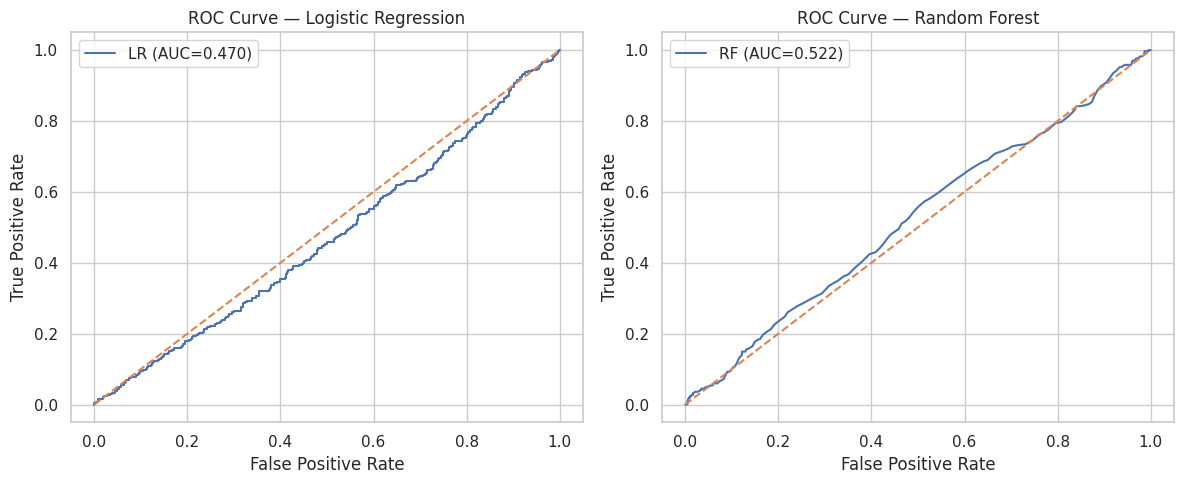

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve

# ROC cho LR và RF
fpr_lr, tpr_lr, _ = roc_curve(y_test, proba_lr)
fpr_rf, tpr_rf, _ = roc_curve(y_test, proba_rf)

fig, axes = plt.subplots(1, 2, figsize=(12,5))  # 1 hàng, 2 cột

# Biểu đồ bên trái — LR
axes[0].plot(fpr_lr, tpr_lr, label=f"LR (AUC={m_lr[2]:.3f})")
axes[0].plot([0,1], [0,1], "--")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("ROC Curve — Logistic Regression")
axes[0].legend()

# Biểu đồ bên phải — RF
axes[1].plot(fpr_rf, tpr_rf, label=f"RF (AUC={m_rf[2]:.3f})")
axes[1].plot([0,1], [0,1], "--")
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].set_title("ROC Curve — Random Forest")
axes[1].legend()

plt.tight_layout()
plt.show()


Mục đích: trực quan khả năng phân biệt giữa hai lớp ở mọi ngưỡng (threshold).


Đường cong càng “ôm” góc trên-trái càng tốt; đường chéo là mức ngẫu nhiên (random).

AUC (Area Under Curve) là thước đo gọn: 0.5 ~ ngẫu nhiên, >0.7 tốt, >0.8 rất tốt.

**Kết quả:**

RF có AUC ≈ 0.52 nhỉnh hơn LR (≈ 0.47), nhưng cả hai vẫn thấp, dữ liệu hiện tại khó phân tách hai nhóm chỉ bằng những đặc trưng đang dùng.

**Kết luận:**

AUC thấp không có nghĩa là phân tích vô nghĩa. Nó cho thấy giới hạn của dữ liệu hiện tại—một phát hiện quan trọng để biện luận trong báo cáo và đề xuất bổ sung đặc trưng.

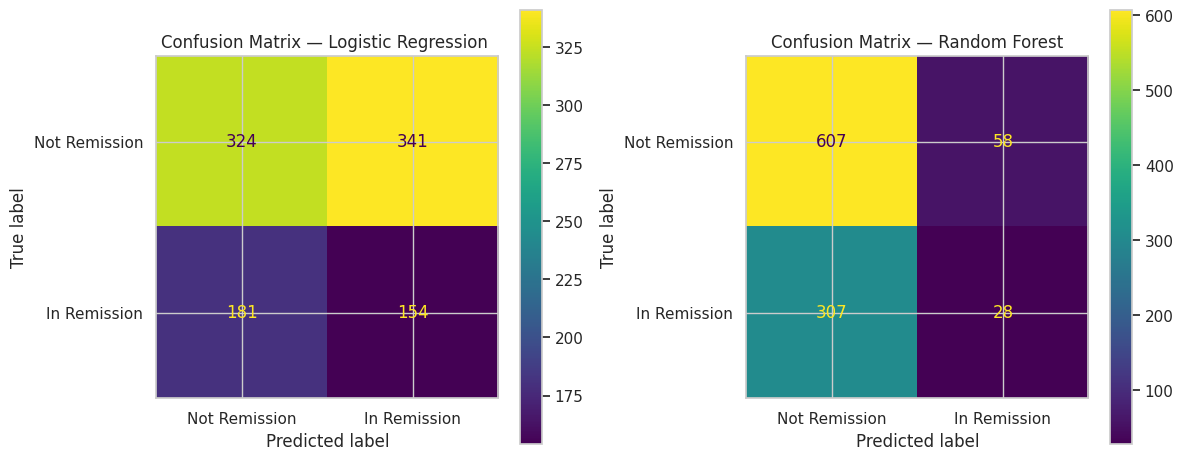

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(12,5))

# Confusion Matrix cho Logistic Regression
ConfusionMatrixDisplay.from_predictions(
    y_test, pred_lr,
    display_labels=["Not Remission", "In Remission"],
    ax=axes[0]
)
axes[0].set_title("Confusion Matrix — Logistic Regression ")

# Confusion Matrix cho Random Forest
ConfusionMatrixDisplay.from_predictions(
    y_test, pred_rf,
    display_labels=["Not Remission", "In Remission"],
    ax=axes[1]
)
axes[1].set_title("Confusion Matrix — Random Forest")

plt.tight_layout()
plt.show()


Mục đích: xem mô hình nhầm lẫn ở đâu—đặc biệt là bao nhiêu ca thuyên giảm bị bỏ sót (False Negative, FN).

Hàng In Remission (true label = 1):

* Ô bên phải là dự đoán đúng (TP),

* Ô bên trái là bị bỏ sót (FN).

Hàng Not Remission (true label = 0):

* Ô bên trái (TN) là đúng, ô bên phải (FP) là dương giả.

Kết quả của bạn (ví dụ):

LR (balanced): TP 154, FN 181 → bắt được kha khá ca thuyên giảm, nhưng vẫn còn bỏ sót.

RF: TP 28, FN 307 → gần như bỏ sót phần lớn ca thuyên giảm.
Thuật ngữ: confusion matrix = ma trận nhầm lẫn; TP/TN/FP/FN = dương/âm thật/giả

**Kết luận:**

Ma trận nhầm lẫn minh họa rõ trade-off: LR hợp với mục tiêu không bỏ sót nhiều; RF hợp với độ chính xác tổng thể nhưng thiên vị lớp đa số.

Với các đặc trưng hiện có, bài toán vẫn khó phân tách hai lớp (*ROC-AUC* ≈ 0.47–0.52 → khả năng phân biệt còn thấp). **Logistic Regression (balanced)** ưu tiên *không bỏ sót* nhóm thuyên giảm (*recall* lớp 1 cao hơn) nên phù hợp mục tiêu phân tích yếu tố và sàng lọc; **Random Forest** cho độ chính xác tổng thể cao hơn nhưng thiên về lớp đa số, chưa phù hợp nếu ưu tiên lâm sàng là phát hiện ca thuyên giảm. Từ đây, giữ **LR (balanced)** làm **baseline** để thử cải thiện (tối ưu *threshold*, cân bằng dữ liệu bằng *SMOTE*/`class_weight`).

Mô hình được thiết kế cho mục đích sàng lọc nội bộ: hỗ trợ bác sĩ/hội chẩn nhận diện ca có khả năng thuyên giảm (ưu tiên không bỏ sót), hỗ trợ điều phối theo dõi bằng phân tầng rủi ro, và cung cấp xu hướng tổng hợp cho quản trị. Mô hình không được dùng để quyết định điều trị hay tư vấn bệnh nhân; muốn triển khai lâm sàng cần bổ sung biến lâm sàng chi tiết và/hoặc áp dụng survival analysis cho mục tiêu thời gian sống.
